In [1]:
import pandas as pd

# Load the files
threat = pd.read_csv("threat_database.csv")

medicare = pd.read_csv(
    "Medicare_IP_Hospitals_by_Provider_2024.csv"
)

# ==========================================
# STEP 5 — PREPARE ANALYSIS DATA
# AND CHECK HOSPITAL DUPLICATION
# ==========================================


print("THREAT dataset shape:")
print(threat.shape)


# ------------------------------------------
# 2. CHECK THE THREAT COLUMN NAMES
# ------------------------------------------

print("\nTHREAT columns:")
print(threat.columns.tolist())


# ------------------------------------------
# 3. LOAD MEDICARE DATA
# ------------------------------------------



print("\nMedicare dataset shape:")
print(medicare.shape)


# ------------------------------------------
# 4. CHECK MEDICARE COLUMN NAMES
# ------------------------------------------

print("\nMedicare columns:")
print(medicare.columns.tolist())


# ------------------------------------------
# 5. CREATE A SMALL MEDICARE TABLE
# ------------------------------------------
# IMPORTANT:
# The Medicare file uses Rndrng_Prvdr_CCN.
# We rename it to CCN so that it matches
# the hospital identifier in the THREAT data.

medicare_small = medicare[
    [
        "Rndrng_Prvdr_CCN",
        "Rndrng_Prvdr_Org_Name",
        "Tot_Benes",
        "Tot_Dschrgs",
        "Tot_Cvrd_Days",
        "Tot_Days",
        "Bene_Avg_Age",
        "Bene_Avg_Risk_Scre"
    ]
].copy()

medicare_small = medicare_small.rename(
    columns={
        "Rndrng_Prvdr_CCN": "CCN"
    }
)


# ------------------------------------------
# 6. MAKE SURE THREAT HAS CCN
# ------------------------------------------
# The THREAT file uses medicare_id.
# We rename it to CCN.

threat = threat.rename(
    columns={
        "medicare_id": "CCN"
    }
)

print("\nTHREAT columns after renaming:")
print(threat.columns.tolist())


# ------------------------------------------
# 7. MERGE THREAT + MEDICARE
# ------------------------------------------

hospital_events = threat.merge(
    medicare_small,
    on="CCN",
    how="left",
    validate="many_to_one"
)

print("\nMerged dataset shape:")
print(hospital_events.shape)


# ------------------------------------------
# 8. CHECK WHETHER MEDICARE MATCHED
# ------------------------------------------

hospital_events["matched_medicare"] = (
    hospital_events["Rndrng_Prvdr_Org_Name"].notna()
)

print("\nMedicare matching:")
print(
    hospital_events["matched_medicare"].value_counts()
)


# ------------------------------------------
# 9. CREATE ANALYSIS DATA
# ------------------------------------------
# We keep only hospitals that successfully
# matched with the Medicare dataset.

analysis_data = hospital_events[
    hospital_events["matched_medicare"] == True
].copy()

print("\n==========================================")
print("ANALYSIS DATA")
print("==========================================")

print("Shape:")
print(analysis_data.shape)

print("\nAttack status:")
print(
    analysis_data["attacked"].value_counts()
)

print("\nUnique hospitals:")
print(
    analysis_data["CCN"].nunique()
)


# ------------------------------------------
# 10. CHECK HOSPITAL DUPLICATION
# ------------------------------------------

hospital_counts = (
    analysis_data
    .groupby("CCN")
    .size()
    .sort_values(ascending=False)
)

print("\n==========================================")
print("HOSPITAL DUPLICATION")
print("==========================================")

print(
    "\nNumber of hospitals with more than one observation:"
)
print(
    (hospital_counts > 1).sum()
)

print(
    "\nMaximum observations for one hospital:"
)
print(
    hospital_counts.max()
)

print(
    "\nObservation count distribution:"
)
print(
    hospital_counts.value_counts().sort_index()
)


# ------------------------------------------
# 11. CHECK REPEATED ATTACKED HOSPITALS
# ------------------------------------------

attacked_only = analysis_data[
    analysis_data["attacked"] == 1
].copy()

attacked_counts = (
    attacked_only
    .groupby("CCN")
    .size()
    .sort_values(ascending=False)
)

print("\n==========================================")
print("REPEATED ATTACKED HOSPITALS")
print("==========================================")

print(
    "\nUnique attacked hospitals:"
)
print(
    attacked_only["CCN"].nunique()
)

print(
    "\nAttacked hospitals with more than one observation:"
)
print(
    attacked_counts[
        attacked_counts > 1
    ]
)

print(
    "\nNumber of attacked hospitals with more than one observation:"
)
print(
    (attacked_counts > 1).sum()
)

THREAT dataset shape:
(4349, 14)

THREAT columns:
['medicare_id', 'attacked', 'attack_date', 'er_diversion', 'cancel_delay', 'threat_id', 'nearest_neighbor', 'origin_threat_id1', 'origin_threat_id2', 'origin_threat_id3', 'origin_threat_id4', 'origin_threat_id5', 'origin_threat_id6', 'origin_threat_id7']

Medicare dataset shape:
(3044, 57)

Medicare columns:
['Rndrng_Prvdr_CCN', 'Rndrng_Prvdr_Org_Name', 'Rndrng_Prvdr_St', 'Rndrng_Prvdr_City', 'Rndrng_Prvdr_Zip5', 'Rndrng_Prvdr_State_Abrvtn', 'Rndrng_Prvdr_State_FIPS', 'Rndrng_Prvdr_RUCA', 'Rndrng_Prvdr_RUCA_Desc', 'Tot_Benes', 'Tot_Submtd_Cvrd_Chrg', 'Tot_Pymt_Amt', 'Tot_Mdcr_Pymt_Amt', 'Tot_Dschrgs', 'Tot_Cvrd_Days', 'Tot_Days', 'Bene_Avg_Age', 'Bene_Age_LT_65_Cnt', 'Bene_Age_65_74_Cnt', 'Bene_Age_75_84_Cnt', 'Bene_Age_GT_84_Cnt', 'Bene_Feml_Cnt', 'Bene_Male_Cnt', 'Bene_Race_Wht_Cnt', 'Bene_Race_Black_Cnt', 'Bene_Race_API_Cnt', 'Bene_Race_Hspnc_Cnt', 'Bene_Race_NatInd_Cnt', 'Bene_Race_Othr_Cnt', 'Bene_Dual_Cnt', 'Bene_Ndual_Cnt', 'Bene

In [2]:
# ==========================================
# STEP 5B — INSPECT REPEATED ATTACKED HOSPITALS
# ==========================================

repeated_ccns = attacked_counts[
    attacked_counts > 1
].index

repeated_attacks = attacked_only[
    attacked_only["CCN"].isin(repeated_ccns)
].copy()

print("Repeated attacked hospital records:")
print(
    repeated_attacks[
        [
            "CCN",
            "attacked",
            "attack_date",
            "threat_id",
            "er_diversion",
            "cancel_delay",
            "nearest_neighbor"
        ]
    ].sort_values(
        ["CCN", "attack_date", "threat_id"]
    ).to_string(index=False)
)

Repeated attacked hospital records:
   CCN  attacked attack_date  threat_id  er_diversion  cancel_delay  nearest_neighbor
 10092         1   10/1/2019      127.0           1.0           0.0                 0
 10092         1   10/1/2019      127.0           1.0           0.0                 0
 50077         1    5/1/2021      248.0           1.0           1.0                 0
 50077         1    5/1/2021      248.0           1.0           1.0                 0
 50701         1   9/27/2020      188.0           1.0           1.0                 0
 50701         1   9/27/2020      188.0           1.0           1.0                 0
180067         1    2/8/2020      142.0           0.0           0.0                 0
180067         1    2/8/2020      142.0           0.0           0.0                 0
280065         1  11/25/2019      132.0           0.0           1.0                 0
280065         1   9/20/2020      186.0           0.0           1.0                 0
290032         1  

In [3]:
# ==========================================
# STEP 6 — CHECK EXACT DUPLICATES
# ==========================================

duplicate_columns = [
    "CCN",
    "attacked",
    "attack_date",
    "er_diversion",
    "cancel_delay",
    "threat_id",
    "nearest_neighbor"
]

exact_duplicates = analysis_data[
    analysis_data.duplicated(
        subset=duplicate_columns,
        keep=False
    )
].copy()

print("Number of rows involved in exact duplicates:")
print(len(exact_duplicates))

print("\nExact duplicate records:")
print(
    exact_duplicates[
        duplicate_columns
    ].sort_values(
        ["CCN", "attack_date", "threat_id"]
    ).to_string(index=False)
)

Number of rows involved in exact duplicates:
20

Exact duplicate records:
   CCN  attacked attack_date  er_diversion  cancel_delay  threat_id  nearest_neighbor
 10092         1   10/1/2019           1.0           0.0      127.0                 0
 10092         1   10/1/2019           1.0           0.0      127.0                 0
 50077         1    5/1/2021           1.0           1.0      248.0                 0
 50077         1    5/1/2021           1.0           1.0      248.0                 0
 50701         1   9/27/2020           1.0           1.0      188.0                 0
 50701         1   9/27/2020           1.0           1.0      188.0                 0
180067         1    2/8/2020           0.0           0.0      142.0                 0
180067         1    2/8/2020           0.0           0.0      142.0                 0
290032         1   9/27/2020           1.0           1.0      188.0                 0
290032         1   9/27/2020           1.0           1.0      188.

In [4]:
# ==========================================
# STEP 6B — UNIQUE HOSPITAL-ATTACK PAIRS
# ==========================================

hospital_attack_pairs = (
    attacked_only[
        ["CCN", "threat_id", "attack_date"]
    ]
    .drop_duplicates()
)

print("Unique hospital-attack pairs:")
print(len(hospital_attack_pairs))

print("\nUnique attacked hospitals:")
print(hospital_attack_pairs["CCN"].nunique())

print("\nUnique attack events:")
print(hospital_attack_pairs["threat_id"].nunique())

Unique hospital-attack pairs:
131

Unique attacked hospitals:
130

Unique attack events:
64


In [5]:
# ==========================================
# STEP 7 — CREATE CLEAN ANALYSIS TABLES
# ==========================================

# ------------------------------------------
# 1. KEEP ONLY ACTUAL ATTACKED OBSERVATIONS
# ------------------------------------------

attacked_events = analysis_data[
    analysis_data["attacked"] == 1
].copy()


# ------------------------------------------
# 2. REMOVE EXACT DUPLICATE
#    HOSPITAL-ATTACK RECORDS
# ------------------------------------------

hospital_attack_events = (
    attacked_events
    .drop_duplicates(
        subset=[
            "CCN",
            "threat_id",
            "attack_date",
            "er_diversion",
            "cancel_delay",
            "nearest_neighbor"
        ]
    )
    .copy()
)


# ------------------------------------------
# 3. CREATE HOSPITAL MASTER TABLE
# ------------------------------------------
# One row = one hospital

hospital_master = (
    analysis_data[
        [
            "CCN",
            "Rndrng_Prvdr_Org_Name",
            "Tot_Benes",
            "Tot_Dschrgs",
            "Tot_Cvrd_Days",
            "Tot_Days",
            "Bene_Avg_Age",
            "Bene_Avg_Risk_Scre"
        ]
    ]
    .drop_duplicates(subset=["CCN"])
    .copy()
)


# ------------------------------------------
# 4. CREATE ATTACK EVENTS TABLE
# ------------------------------------------
# One row = one ransomware attack event
#
# Only use rows with a valid threat_id.

attack_events = (
    hospital_attack_events[
        ["threat_id", "attack_date"]
    ]
    .dropna(subset=["threat_id"])
    .drop_duplicates(subset=["threat_id"])
    .copy()
)


# ------------------------------------------
# 5. FINAL CHECK
# ------------------------------------------

print("==========================================")
print("FINAL DATASET CHECK")
print("==========================================")

print(
    "\nHospital master rows:",
    len(hospital_master)
)

print(
    "Unique hospitals:",
    hospital_master["CCN"].nunique()
)

print(
    "\nHospital-attack event rows:",
    len(hospital_attack_events)
)

print(
    "Unique attacked hospitals:",
    hospital_attack_events["CCN"].nunique()
)

print(
    "\nAttack event rows:",
    len(attack_events)
)

print(
    "Unique attack events:",
    attack_events["threat_id"].nunique()
)


# ------------------------------------------
# 6. SHOW TABLES
# ------------------------------------------

print("\n==========================================")
print("HOSPITAL MASTER")
print("==========================================")

print(hospital_master.head())


print("\n==========================================")
print("HOSPITAL-ATTACK EVENTS")
print("==========================================")

print(
    hospital_attack_events[
        [
            "CCN",
            "attack_date",
            "threat_id",
            "er_diversion",
            "cancel_delay",
            "nearest_neighbor"
        ]
    ].head(10)
)


print("\n==========================================")
print("ATTACK EVENTS")
print("==========================================")

print(attack_events.head(10))

FINAL DATASET CHECK

Hospital master rows: 2791
Unique hospitals: 2791

Hospital-attack event rows: 131
Unique attacked hospitals: 130

Attack event rows: 64
Unique attack events: 64

HOSPITAL MASTER
     CCN                  Rndrng_Prvdr_Org_Name  Tot_Benes  Tot_Dschrgs  \
0  10045                 Fayette Medical Center      159.0        197.0   
1  10092            Dch Regional Medical Center     3199.0       4704.0   
3  10144           Springhill Memorial Hospital     1340.0       1760.0   
4  50039                           Enloe Health     5112.0       7674.0   
5  50063  Hollywood Presbyterian Medical Center     1584.0       2013.0   

   Tot_Cvrd_Days  Tot_Days  Bene_Avg_Age  Bene_Avg_Risk_Scre  
0          669.0     676.0     78.911950            1.866420  
1        27286.0   28572.0     74.085652            2.164718  
3         9002.0    9247.0     75.947761            2.122711  
4        35074.0   35379.0     75.753912            1.980061  
5        12049.0   12263.0     77.

In [6]:
# ==========================================
# STEP 8 — AUDIT ATTACK CHARACTERISTICS
# ==========================================

print("==========================================")
print("ATTACK CHARACTERISTICS")
print("==========================================")


# ------------------------------------------
# 1. ER DIVERSION
# ------------------------------------------

print("\nER diversion:")
print(
    hospital_attack_events["er_diversion"]
    .value_counts(dropna=False)
    .sort_index()
)


# ------------------------------------------
# 2. CANCELLATION / DELAY
# ------------------------------------------

print("\nCancellation / delay:")
print(
    hospital_attack_events["cancel_delay"]
    .value_counts(dropna=False)
    .sort_index()
)


# ------------------------------------------
# 3. BOTH INDICATORS
# ------------------------------------------

print("\nER diversion + cancellation/delay:")
print(
    hospital_attack_events[
        ["er_diversion", "cancel_delay"]
    ]
    .value_counts(dropna=False)
)


# ------------------------------------------
# 4. ATTACK-LEVEL SUMMARY
# ------------------------------------------
# Some attacks affect multiple hospitals.
# Therefore, we calculate the number of
# affected hospitals per attack.

hospitals_per_attack = (
    hospital_attack_events
    .groupby("threat_id")["CCN"]
    .nunique()
    .sort_values(ascending=False)
)

print("\n==========================================")
print("HOSPITALS AFFECTED PER ATTACK")
print("==========================================")

print(
    hospitals_per_attack.describe()
)

print("\nLargest attack events:")
print(
    hospitals_per_attack.head(10)
)


# ------------------------------------------
# 5. ATTACK DATE RANGE
# ------------------------------------------

hospital_attack_events["attack_date_clean"] = pd.to_datetime(
    hospital_attack_events["attack_date"],
    errors="coerce"
)

print("\n==========================================")
print("ATTACK DATE RANGE")
print("==========================================")

print(
    "Earliest attack:",
    hospital_attack_events["attack_date_clean"].min()
)

print(
    "Latest attack:",
    hospital_attack_events["attack_date_clean"].max()
)

ATTACK CHARACTERISTICS

ER diversion:
er_diversion
0.0    93
1.0    38
Name: count, dtype: int64

Cancellation / delay:
cancel_delay
0.0    63
1.0    68
Name: count, dtype: int64

ER diversion + cancellation/delay:
er_diversion  cancel_delay
0.0           0.0             55
              1.0             38
1.0           1.0             30
              0.0              8
Name: count, dtype: int64

HOSPITALS AFFECTED PER ATTACK
count    64.000000
mean      2.046875
std       3.077980
min       1.000000
25%       1.000000
50%       1.000000
75%       1.000000
max      20.000000
Name: CCN, dtype: float64

Largest attack events:
threat_id
188.0    20
133.0    11
263.0     9
7.0       9
264.0     8
248.0     4
186.0     4
28.0      3
135.0     2
259.0     2
Name: CCN, dtype: int64

ATTACK DATE RANGE
Earliest attack: 2016-01-15 00:00:00
Latest attack: 2021-12-17 00:00:00


In [7]:
# ==========================================
# STEP 9 — ATTACK SCOPE VS OPERATIONAL IMPACT
# ==========================================

attack_scope = (
    hospital_attack_events
    .groupby("threat_id")["CCN"]
    .nunique()
    .rename("hospitals_affected")
    .reset_index()
)

attack_summary = (
    hospital_attack_events[
        ["threat_id", "er_diversion", "cancel_delay"]
    ]
    .merge(
        attack_scope,
        on="threat_id",
        how="left"
    )
)

print("==========================================")
print("ATTACK SCOPE SUMMARY")
print("==========================================")

print(
    attack_summary[
        ["hospitals_affected"]
    ].describe()
)

print("\n==========================================")
print("OPERATIONAL IMPACT BY ATTACK SCOPE")
print("==========================================")

print(
    attack_summary
    .groupby("hospitals_affected")[
        ["er_diversion", "cancel_delay"]
    ]
    .mean()
)

ATTACK SCOPE SUMMARY
       hospitals_affected
count          131.000000
mean             6.603053
std              6.707836
min              1.000000
25%              1.000000
50%              3.000000
75%              9.000000
max             20.000000

OPERATIONAL IMPACT BY ATTACK SCOPE
                    er_diversion  cancel_delay
hospitals_affected                            
1                       0.244898      0.285714
2                       0.142857      0.428571
3                       0.000000      0.000000
4                       0.500000      1.000000
8                       0.000000      0.000000
9                       0.000000      0.500000
11                      0.000000      1.000000
20                      1.000000      1.000000


In [9]:
# ==========================================
# STEP 8 — CREATE OPERATIONAL DISRUPTION TARGET
# ==========================================

# Make sure the outcome columns are numeric
hospital_attack_events["er_diversion"] = (
    hospital_attack_events["er_diversion"].astype(int)
)

hospital_attack_events["cancel_delay"] = (
    hospital_attack_events["cancel_delay"].astype(int)
)

# Operational disruption severity:
# 0 = neither outcome occurred
# 1 = one outcome occurred
# 2 = both outcomes occurred

hospital_attack_events["disruption_severity"] = (
    hospital_attack_events["er_diversion"]
    + hospital_attack_events["cancel_delay"]
)

severity_labels = {
    0: "Low",
    1: "Moderate",
    2: "High"
}

hospital_attack_events["severity_label"] = (
    hospital_attack_events["disruption_severity"]
    .map(severity_labels)
)

print("Severity distribution:")
print(
    hospital_attack_events[
        "severity_label"
    ].value_counts()
)

print("\nNumeric severity:")
print(
    hospital_attack_events[
        "disruption_severity"
    ].value_counts().sort_index()
)

Severity distribution:
severity_label
Low         55
Moderate    46
High        30
Name: count, dtype: int64

Numeric severity:
disruption_severity
0    55
1    46
2    30
Name: count, dtype: int64


In [10]:
# ==========================================
# STEP 9 — CREATE ATTACK SCOPE FEATURE
# ==========================================

hospitals_per_attack = (
    hospital_attack_events
    .groupby("threat_id")["CCN"]
    .nunique()
    .rename("hospitals_affected")
)

hospital_attack_events = (
    hospital_attack_events
    .merge(
        hospitals_per_attack,
        on="threat_id",
        how="left"
    )
)

print(
    hospital_attack_events[
        [
            "CCN",
            "threat_id",
            "hospitals_affected",
            "disruption_severity"
        ]
    ].head(10)
)

     CCN  threat_id  hospitals_affected  disruption_severity
0  10045      127.0                   2                    1
1  10092      127.0                   2                    1
2  10144      113.0                   1                    0
3  50039      139.0                   1                    1
4  50063        3.0                   1                    1
5  50077      248.0                   4                    2
6  50204      188.0                  20                    2
7  50324      248.0                   4                    2
8  50329      188.0                  20                    2
9  50424      248.0                   4                    2


In [11]:
# ==========================================
# STEP 10 — FEATURE ENGINEERING
# ==========================================

import numpy as np

hospital_attack_events["avg_length_of_stay"] = (
    hospital_attack_events["Tot_Cvrd_Days"]
    / hospital_attack_events["Tot_Dschrgs"]
)

# Replace infinite values if denominator was zero
hospital_attack_events[
    "avg_length_of_stay"
] = hospital_attack_events[
    "avg_length_of_stay"
].replace([np.inf, -np.inf], np.nan)

print(
    hospital_attack_events[
        [
            "Tot_Benes",
            "Tot_Dschrgs",
            "Tot_Cvrd_Days",
            "Bene_Avg_Risk_Scre",
            "avg_length_of_stay"
        ]
    ].describe()
)

          Tot_Benes   Tot_Dschrgs  Tot_Cvrd_Days  Bene_Avg_Risk_Scre  \
count    131.000000    131.000000     131.000000          131.000000   
mean    2081.175573   2794.732824   15302.587786            2.141285   
std     1745.933092   2393.647924   16110.549362            0.333653   
min       12.000000     12.000000      60.000000            1.504833   
25%      890.000000   1191.000000    5455.000000            1.893898   
50%     1693.000000   2203.000000   11409.000000            2.117868   
75%     2709.500000   3550.500000   18667.000000            2.318029   
max    11235.000000  15416.000000  117501.000000            3.115830   

       avg_length_of_stay  
count          131.000000  
mean             5.008965  
std              1.144036  
min              2.787966  
25%              4.251008  
50%              4.843473  
75%              5.609687  
max              9.123521  


In [12]:
# ==========================================
# STEP 11 — CREATE ML DATASET
# ==========================================

model_columns = [
    # Identifiers - kept for grouping/tracking
    "CCN",
    "threat_id",

    # Hospital predictors
    "Tot_Benes",
    "Tot_Dschrgs",
    "Tot_Cvrd_Days",
    "Bene_Avg_Risk_Scre",
    "avg_length_of_stay",

    # Attack predictor
    "hospitals_affected",

    # Target
    "disruption_severity"
]

model_data = hospital_attack_events[
    model_columns
].copy()

print("Model dataset shape:")
print(model_data.shape)

print("\nMissing values:")
print(model_data.isna().sum())

print("\nFirst 10 rows:")
print(model_data.head(10))

print("\nSeverity distribution:")
print(
    model_data[
        "disruption_severity"
    ].value_counts().sort_index()
)

Model dataset shape:
(131, 9)

Missing values:
CCN                    0
threat_id              0
Tot_Benes              0
Tot_Dschrgs            0
Tot_Cvrd_Days          0
Bene_Avg_Risk_Scre     0
avg_length_of_stay     0
hospitals_affected     0
disruption_severity    0
dtype: int64

First 10 rows:
     CCN  threat_id  Tot_Benes  Tot_Dschrgs  Tot_Cvrd_Days  \
0  10045      127.0      159.0        197.0          669.0   
1  10092      127.0     3199.0       4704.0        27286.0   
2  10144      113.0     1340.0       1760.0         9002.0   
3  50039      139.0     5112.0       7674.0        35074.0   
4  50063        3.0     1584.0       2013.0        12049.0   
5  50077      248.0     3406.0       4563.0        24295.0   
6  50204      188.0     1341.0       1797.0         9502.0   
7  50324      248.0     5781.0       7469.0        36551.0   
8  50329      188.0     1067.0       1452.0         6862.0   
9  50424      248.0     2707.0       3353.0        13420.0   

   Bene_Avg_Risk

In [18]:
print(model_data.isna().sum())


CCN                    0
threat_id              0
Tot_Benes              0
Tot_Dschrgs            0
Tot_Cvrd_Days          0
Bene_Avg_Risk_Scre     0
avg_length_of_stay     0
hospitals_affected     0
disruption_severity    0
dtype: int64


In [16]:
# ==========================================
# STEP 12 — FINAL DATA INTEGRITY CHECK
# ==========================================

print("Rows:", len(model_data))

print(
    "Unique hospitals:",
    model_data["CCN"].nunique()
)

print(
    "Unique ransomware events:",
    model_data["threat_id"].nunique()
)

print("\nSeverity:")
print(
    model_data[
        "disruption_severity"
    ].value_counts().sort_index()
)

print("\nDuplicate hospital-attack pairs:")
print(
    model_data.duplicated(
        subset=["CCN", "threat_id"]
    ).sum()
)

Rows: 131
Unique hospitals: 130
Unique ransomware events: 64

Severity:
disruption_severity
0    55
1    46
2    30
Name: count, dtype: int64

Duplicate hospital-attack pairs:
0


Feature correlation matrix:
                    Tot_Benes  Tot_Dschrgs  Tot_Cvrd_Days  Bene_Avg_Risk_Scre  \
Tot_Benes                1.00         1.00           0.97                0.14   
Tot_Dschrgs              1.00         1.00           0.97                0.15   
Tot_Cvrd_Days            0.97         0.97           1.00                0.20   
Bene_Avg_Risk_Scre       0.14         0.15           0.20                1.00   
avg_length_of_stay       0.49         0.48           0.59                0.52   

                    avg_length_of_stay  
Tot_Benes                         0.49  
Tot_Dschrgs                       0.48  
Tot_Cvrd_Days                     0.59  
Bene_Avg_Risk_Scre                0.52  
avg_length_of_stay                1.00  


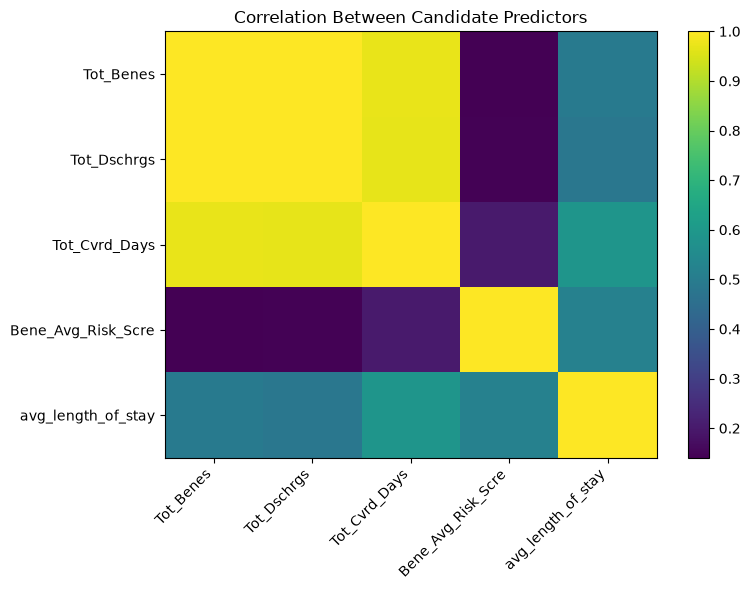

In [20]:
# ==========================================
# STEP 13 — CHECK FEATURE CORRELATION
# ==========================================

import matplotlib.pyplot as plt

feature_check = model_data[
    [
        "Tot_Benes",
        "Tot_Dschrgs",
        "Tot_Cvrd_Days",
        "Bene_Avg_Risk_Scre",
        "avg_length_of_stay"
    ]
]

correlation_matrix = feature_check.corr()

print("Feature correlation matrix:")
print(correlation_matrix.round(2))

plt.figure(figsize=(8, 6))

plt.imshow(
    correlation_matrix,
    aspect="auto"
)

plt.colorbar()

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

plt.title("Correlation Between Candidate Predictors")

plt.tight_layout()
plt.show()

In [23]:
print(correlation_matrix.round(2))

                    Tot_Benes  Tot_Dschrgs  Tot_Cvrd_Days  Bene_Avg_Risk_Scre  \
Tot_Benes                1.00         1.00           0.97                0.14   
Tot_Dschrgs              1.00         1.00           0.97                0.15   
Tot_Cvrd_Days            0.97         0.97           1.00                0.20   
Bene_Avg_Risk_Scre       0.14         0.15           0.20                1.00   
avg_length_of_stay       0.49         0.48           0.59                0.52   

                    avg_length_of_stay  
Tot_Benes                         0.49  
Tot_Dschrgs                       0.48  
Tot_Cvrd_Days                     0.59  
Bene_Avg_Risk_Scre                0.52  
avg_length_of_stay                1.00  


In [22]:
# ==========================================
# STEP 14 — FEATURE SUMMARY BY SEVERITY
# ==========================================

feature_columns = [
    "Tot_Benes",
    "Tot_Dschrgs",
    "Tot_Cvrd_Days",
    "Bene_Avg_Risk_Scre",
    "avg_length_of_stay"
]

severity_summary = (
    model_data
    .groupby("disruption_severity")[feature_columns]
    .median()
)

print("Median predictor values by disruption severity:")
print(severity_summary.round(2))

Median predictor values by disruption severity:
                     Tot_Benes  Tot_Dschrgs  Tot_Cvrd_Days  \
disruption_severity                                          
0                       1181.0       1574.0         7829.0   
1                       2119.0       3044.0        14348.5   
2                       1871.0       2425.5        12678.0   

                     Bene_Avg_Risk_Scre  avg_length_of_stay  
disruption_severity                                          
0                                  2.08                4.63  
1                                  2.10                4.99  
2                                  2.15                4.81  


In [24]:
model_data.to_csv(
    "hospital_ransomware_model_data.csv",
    index=False
)